In [1]:
!wget -q -O sp.zip "https://archive.ics.uci.edu/static/public/320/student+performance.zip"
!unzip -o sp.zip -d uci
!unzip -o uci/student.zip -d uci
!ls uci

Archive:  sp.zip
 extracting: uci/.student.zip_old    
 extracting: uci/student.zip         
Archive:  uci/student.zip
  inflating: uci/student-mat.csv     
  inflating: uci/student-por.csv     
  inflating: uci/student-merge.R     
  inflating: uci/student.txt         
student-mat.csv  student-merge.R  student-por.csv  student.txt	student.zip


In [2]:
import numpy as np
import pandas as pd

df = pd.read_csv("uci/student-mat.csv", sep=";")
print(df.shape)
print(df[["studytime", "failures", "absences", "G1", "G2", "G3"]].head())
print("missing values:", df.isnull().sum().sum())

(395, 33)
   studytime  failures  absences  G1  G2  G3
0          2         0         6   5   6   6
1          2         0         4   5   5   6
2          2         3        10   7   8  10
3          3         0         2  15  14  15
4          2         0         4   6  10  10
missing values: 0


In [3]:
features = ["studytime", "failures", "absences", "G1", "G2"]
target = "G3"

X = df[features].to_numpy(dtype=float)
y = df[target].to_numpy(dtype=float)
print(X.shape, y.shape)

(395, 5) (395,)


In [4]:
rng = np.random.default_rng(42)
idx = rng.permutation(len(X))

split = int(0.8 * len(X))
train_idx, test_idx = idx[:split], idx[split:]

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]
print(X_train.shape, X_test.shape)

(316, 5) (79, 5)


In [5]:
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

print("train mean:", X_train.mean(axis=0).round(3))
print("train std: ", X_train.std(axis=0).round(3))

train mean: [ 0.  0. -0.  0.  0.]
train std:  [1. 1. 1. 1. 1.]


In [6]:
def predict(X, w, b):
    return X @ w + b

def mse(y_true, y_pred):
    return np.mean((y_pred - y_true) ** 2)

# Starting guess: all weights zero, bias zero
w = np.zeros(X_train.shape[1])
b = 0.0

print("initial loss:", mse(y_train, predict(X_train, w, b)))

# Benchmark: a model that always predicts the average grade
baseline = np.full_like(y_train, y_train.mean())
print("baseline loss (always predict the mean):", mse(y_train, baseline))

initial loss: 122.9113924050633
baseline loss (always predict the mean): 20.619932703092452


In [7]:
def gradients(X, y, w, b):
    n = len(y)
    error = predict(X, w, b) - y
    dw = (2 / n) * (X.T @ error)
    db = (2 / n) * np.sum(error)
    return dw, db

dw, db = gradients(X_train, y_train, w, b)
print("dw:", dw)
print("db:", db)

dw: [-0.76745062  3.32752021 -0.26695291 -7.16613782 -8.1883033 ]
db: -20.227848101265824


In [8]:
def numeric_grad_w(X, y, w, b, j, eps=1e-5):
    w_plus = w.copy();  w_plus[j] += eps
    w_minus = w.copy(); w_minus[j] -= eps
    return (mse(y, predict(X, w_plus, b)) - mse(y, predict(X, w_minus, b))) / (2 * eps)

for j in range(len(features)):
    print(features[j], dw[j], numeric_grad_w(X_train, y_train, w, b, j))

eps = 1e-5
print("bias", db, (mse(y_train, predict(X_train, w, b + eps)) - mse(y_train, predict(X_train, w, b - eps))) / (2 * eps))

studytime -0.7674506200632465 -0.7674506200316954
failures 3.3275202078910042 3.3275202085292217
absences -0.2669529105846983 -0.2669529102661272
G1 -7.166137816262577 -7.166137816483341
G2 -8.188303300057415 -8.188303301182032
bias -20.227848101265824 -20.22784810051803


In [9]:
def train(X, y, lr=0.1, n_iter=500):
    w = np.zeros(X.shape[1])
    b = 0.0
    history = []
    for it in range(n_iter):
        dw, db = gradients(X, y, w, b)
        w -= lr * dw
        b -= lr * db
        history.append(mse(y, predict(X, w, b)))
        if it % 50 == 0 or it == n_iter - 1:
            print(f"iter {it:4d}  loss {history[-1]:.4f}")
    return w, b, history

w_gd, b_gd, history = train(X_train, y_train, lr=0.1, n_iter=500)
print("weights:", dict(zip(features, w_gd.round(4))))
print("bias:", round(b_gd, 4))

iter    0  loss 75.7593
iter   50  loss 3.6187
iter  100  loss 3.5926
iter  150  loss 3.5917
iter  200  loss 3.5916
iter  250  loss 3.5916
iter  300  loss 3.5916
iter  350  loss 3.5916
iter  400  loss 3.5916
iter  450  loss 3.5916
iter  499  loss 3.5916
weights: {'studytime': np.float64(-0.186), 'failures': np.float64(-0.2632), 'absences': np.float64(0.319), 'G1': np.float64(0.4989), 'G2': np.float64(3.6226)}
bias: 10.1139


In [10]:
from sklearn.linear_model import LinearRegression

sk = LinearRegression().fit(X_train, y_train)

print("sklearn weights:", dict(zip(features, sk.coef_.round(4))))
print("sklearn bias:   ", round(sk.intercept_, 4))
print("mine weights:   ", dict(zip(features, w_gd.round(4))))
print("mine bias:      ", round(b_gd, 4))
print("max weight difference:", np.max(np.abs(sk.coef_ - w_gd)))

def report(name, y_true, y_pred):
    mae = np.mean(np.abs(y_true - y_pred))
    rmse = np.sqrt(mse(y_true, y_pred))
    r2 = 1 - np.sum((y_true - y_pred) ** 2) / np.sum((y_true - y_true.mean()) ** 2)
    print(f"{name}: MAE {mae:.3f}  RMSE {rmse:.3f}  R2 {r2:.3f}")

report("mine (test)   ", y_test, predict(X_test, w_gd, b_gd))
report("sklearn (test)", y_test, sk.predict(X_test))

sklearn weights: {'studytime': np.float64(-0.186), 'failures': np.float64(-0.2632), 'absences': np.float64(0.319), 'G1': np.float64(0.4989), 'G2': np.float64(3.6226)}
sklearn bias:    10.1139
mine weights:    {'studytime': np.float64(-0.186), 'failures': np.float64(-0.2632), 'absences': np.float64(0.319), 'G1': np.float64(0.4989), 'G2': np.float64(3.6226)}
mine bias:       10.1139
max weight difference: 1.1272294225816992e-07
mine (test)   : MAE 1.103  RMSE 1.892  R2 0.824
sklearn (test): MAE 1.103  RMSE 1.892  R2 0.824


In [11]:
def run(feats, lr=0.1, n_iter=2000):
    Xa = df[feats].to_numpy(dtype=float)
    Xtr, Xte = Xa[train_idx], Xa[test_idx]
    m, s = Xtr.mean(axis=0), Xtr.std(axis=0)
    Xtr, Xte = (Xtr - m) / s, (Xte - m) / s
    w_, b_ = np.zeros(Xtr.shape[1]), 0.0
    for _ in range(n_iter):
        dw_, db_ = gradients(Xtr, y_train, w_, b_)
        w_ -= lr * dw_
        b_ -= lr * db_
    return predict(Xte, w_, b_)

base = ["age", "Medu", "Fedu", "traveltime", "studytime", "failures",
        "famrel", "freetime", "goout", "Dalc", "Walc", "health", "absences"]

report("A: studytime, failures, absences, G1, G2", y_test, run(["studytime", "failures", "absences", "G1", "G2"]))
report("B: background only (no G1, G2)          ", y_test, run(base))
report("C: background + G1                       ", y_test, run(base + ["G1"]))

A: studytime, failures, absences, G1, G2: MAE 1.103  RMSE 1.892  R2 0.824
B: background only (no G1, G2)          : MAE 3.472  RMSE 4.349  R2 0.072
C: background + G1                       : MAE 1.768  RMSE 2.502  R2 0.693


In [12]:
from sklearn.ensemble import RandomForestRegressor

def standardise(Xtr, Xte):
    m, s = Xtr.mean(axis=0), Xtr.std(axis=0)
    return (Xtr - m) / s, (Xte - m) / s

def fit_gd(Xtr, ytr, lr=0.1, n_iter=2000):
    w_, b_ = np.zeros(Xtr.shape[1]), 0.0
    for _ in range(n_iter):
        dw_, db_ = gradients(Xtr, ytr, w_, b_)
        w_ -= lr * dw_
        b_ -= lr * db_
    return w_, b_

def r2(y_true, y_pred):
    return 1 - np.sum((y_true - y_pred) ** 2) / np.sum((y_true - y_true.mean()) ** 2)

def kfold_scores(feats, k=5, seed=42):
    Xa = df[feats].to_numpy(dtype=float)
    ya = df[target].to_numpy(dtype=float)
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(Xa))
    folds = np.array_split(idx, k)
    lin, rf = [], []
    for i in range(k):
        te = folds[i]
        tr = np.concatenate([folds[j] for j in range(k) if j != i])
        Xtr, Xte = standardise(Xa[tr], Xa[te])
        w_, b_ = fit_gd(Xtr, ya[tr])
        lin.append(r2(ya[te], predict(Xte, w_, b_)))
        rf_model = RandomForestRegressor(n_estimators=200, random_state=42).fit(Xa[tr], ya[tr])
        rf.append(r2(ya[te], rf_model.predict(Xa[te])))
    return np.array(lin), np.array(rf)

setups = {
    "A: studytime, failures, absences, G1, G2": ["studytime", "failures", "absences", "G1", "G2"],
    "B: background only (no G1, G2)": base,
}
for name, feats in setups.items():
    lin, rf = kfold_scores(feats)
    print(name)
    print(f"  Linear (mine, GD): mean R2 {lin.mean():.3f}  std {lin.std():.3f}  folds {lin.round(3)}")
    print(f"  Random Forest:     mean R2 {rf.mean():.3f}  std {rf.std():.3f}  folds {rf.round(3)}")

A: studytime, failures, absences, G1, G2
  Linear (mine, GD): mean R2 0.822  std 0.038  folds [0.759 0.807 0.87  0.848 0.824]
  Random Forest:     mean R2 0.860  std 0.049  folds [0.897 0.773 0.917 0.857 0.855]
B: background only (no G1, G2)
  Linear (mine, GD): mean R2 0.087  std 0.066  folds [ 0.069 -0.007  0.105  0.197  0.072]
  Random Forest:     mean R2 0.205  std 0.074  folds [0.209 0.125 0.207 0.336 0.147]


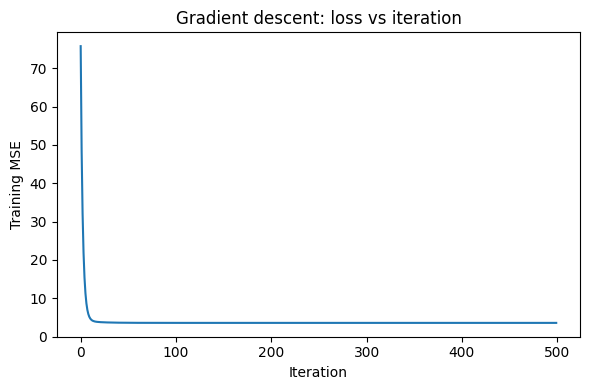

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
plt.plot(history)
plt.xlabel("Iteration")
plt.ylabel("Training MSE")
plt.title("Gradient descent: loss vs iteration")
plt.tight_layout()
plt.savefig("loss_curve.png", dpi=150)
plt.show()

In [14]:
from google.colab import files
files.download("loss_curve.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>